In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

reviews = pd.read_csv("../data/restaurant_reviews.csv")
metadata = pd.read_csv("../data/restaurant_metadata.csv")
print("Reviews Data".center(40,"="))
print(reviews.info())
print("\n")
print("Meta Data".center(40,"="))
print(metadata.info())
print()
print("Checking Dataset size".center(40,"="))
print("Rows in reviews data", reviews.shape[0])
print("Cols in reviews data", reviews.shape[1])
print("Rows in meta data", reviews.shape[0])
print("Cols in meta data", reviews.shape[1])
print("\n")
print(reviews.head())
print(metadata.head())
print("\n")

==============Reviews Data==============
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 547.0+ KB
None


===============Meta Data================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 

In [24]:
print(reviews.describe(include = 'all'))
print(metadata.describe(include='all'))

             Restaurant     Reviewer Review Rating  Metadata             Time  \
count             10000         9962   9955   9962      9962             9962   
unique              100         7446   9364     10      2477             9782   
top     Beyond Flavours  Parijat Ray   good      5  1 Review  7/29/2018 20:34   
freq                100           13    237   3832       919                3   
mean                NaN          NaN    NaN    NaN       NaN              NaN   
std                 NaN          NaN    NaN    NaN       NaN              NaN   
min                 NaN          NaN    NaN    NaN       NaN              NaN   
25%                 NaN          NaN    NaN    NaN       NaN              NaN   
50%                 NaN          NaN    NaN    NaN       NaN              NaN   
75%                 NaN          NaN    NaN    NaN       NaN              NaN   
max                 NaN          NaN    NaN    NaN       NaN              NaN   

            Pictures  
coun

In [36]:
# Dataquality investigation
print("Identifying Null Values".center(40,"="))
print(reviews.isnull().sum())

print("\n")
print("Identifying Null Values %".center(40,"="))
print((reviews.isnull().mean() * 100).round(2))

========Identifying Null Values=========
Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64


=======Identifying Null Values %========
Restaurant    0.00
Reviewer      0.38
Review        0.45
Rating        0.38
Metadata      0.38
Time          0.38
Pictures      0.00
dtype: float64


In [37]:
# Duplicate records
reviews.duplicated().sum()

36

In [41]:
reviews.duplicated(subset = ["Restaurant","Reviewer","Review"]).sum()

42

In [42]:
reviews.columns.tolist()

['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']

In [45]:
# Rating Distribution
reviews["Rating"].value_counts().sort_index()

Rating
1       1735
1.5        9
2        684
2.5       19
3       1193
3.5       47
4       2373
4.5       69
5       3832
Like       1
Name: count, dtype: int64

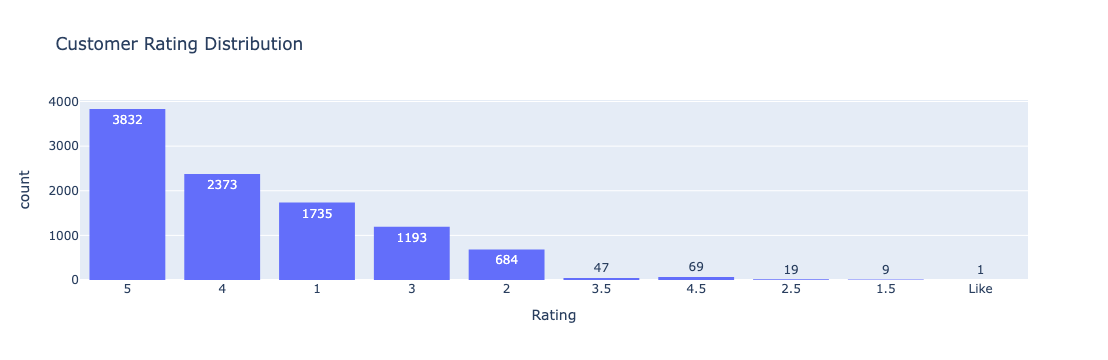

In [47]:
fig = px.histogram(
    reviews,
    x = "Rating",
    title = "Customer Rating Distribution",
    text_auto = True
)
fig.show()

In [48]:
metadata["Name"].duplicated().sum()

0

In [49]:
reviews["Restaurant"].nunique()

100

In [50]:
reviews["Restaurant"].isin(metadata["Name"]).mean() * 100

100.0

In [51]:
metadata.shape

(105, 6)